# Customer Churn Prediction

**Author:** Protik Deb  
**Focus:** Exploratory Data Analysis, classification, model evaluation, and responsible interpretation.

This notebook follows a reproducible workflow on the IBM Telco Customer Churn sample dataset. It compares Logistic Regression and Random Forest using a stratified hold-out set.

> The dataset is a historical sample for a fictional telecom provider. Model metrics are produced when the notebook is executed; no results are assumed in advance.

## 1. Imports and configuration

The workflow uses scikit-learn pipelines so imputation, scaling, and categorical encoding are fitted using training data only.

In [1]:
from pathlib import Path
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
REPO_ROOT = Path.cwd()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
DATA_DIR = REPO_ROOT / "data"
DATA_PATH = DATA_DIR / "Telco-Customer-Churn.csv"
DATA_URL = (
    "https://raw.githubusercontent.com/IBM/"
    "telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
)

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

## 2. Load the dataset

The CSV is downloaded from IBM's public sample-data repository if it is not already present locally. The repository is archived, so keep a local copy if the source becomes unavailable.

Source: [IBM Telco Customer Churn sample](https://github.com/IBM/telco-customer-churn-on-icp4d).

In [2]:
DATA_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    print("Downloading the IBM Telco Customer Churn sample...")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

df = pd.read_csv(DATA_PATH)
print(f"Dataset shape: {df.shape}")
display(df.head())

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Initial data quality review

Check column types, missingness, duplicate rows, and the target distribution before modeling.

In [3]:
display(df.info())
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_values").head(10))
print("Duplicate rows:", df.duplicated().sum())
print("\nTarget counts:")
display(df["Churn"].value_counts(dropna=False).to_frame("count"))
print("\nTarget proportions:")
display((df["Churn"].value_counts(normalize=True) * 100).round(2).to_frame("percent"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


None

,missing_values
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Duplicate rows: 0

Target counts:


,count
Churn,
No,5174
Yes,1869



Target proportions:


,percent
Churn,
No,73.46
Yes,26.54


## 4. Cleaning and feature/target separation

- Remove exact duplicate rows.
- Convert `TotalCharges` to numeric; blank strings become missing values.
- Exclude `customerID`, which is an identifier rather than a meaningful predictor.
- Encode the outcome as 1 = churn, 0 = retained.

Missing numeric and categorical predictor values are imputed inside the model pipeline.

In [4]:
data = df.drop_duplicates().copy()

data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")
data["Churn"] = data["Churn"].map({"No": 0, "Yes": 1})

if data["Churn"].isna().any():
    raise ValueError("Unexpected values in the Churn target column.")

target = data["Churn"].astype(int)
drop_cols = ["Churn", "customerID"]
features = data.drop(columns=[c for c in drop_cols if c in data.columns])

print("Rows after duplicate removal:", len(data))
print("Missing TotalCharges:", data["TotalCharges"].isna().sum())
print("Feature matrix shape:", features.shape)
print("Churn rate: {:.1%}".format(target.mean()))

Rows after duplicate removal: 7043
Missing TotalCharges: 11
Feature matrix shape: (7043, 19)
Churn rate: 26.5%


## 5. Exploratory data analysis

These plots describe the sample and should not be interpreted as causal evidence.

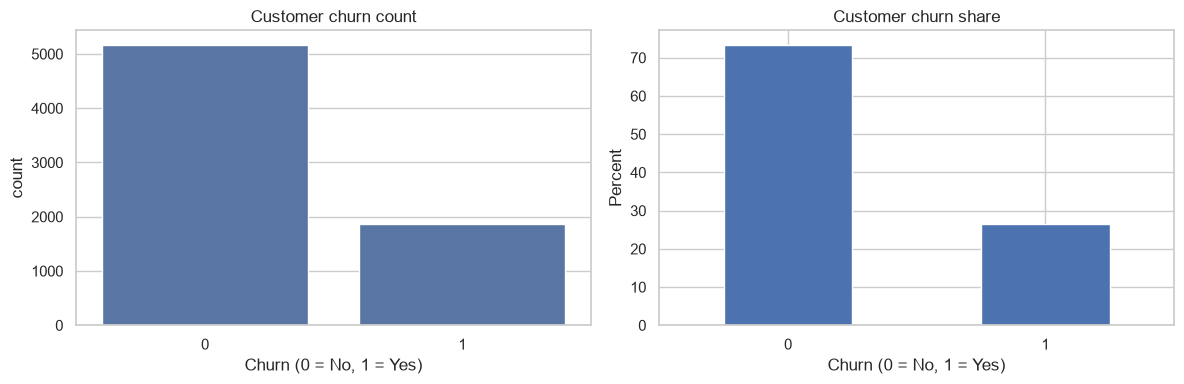

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=data, x="Churn", ax=axes[0])
axes[0].set_title("Customer churn count")
axes[0].set_xlabel("Churn (0 = No, 1 = Yes)")

(data["Churn"].value_counts(normalize=True).sort_index() * 100).plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Customer churn share")
axes[1].set_xlabel("Churn (0 = No, 1 = Yes)")
axes[1].set_ylabel("Percent")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

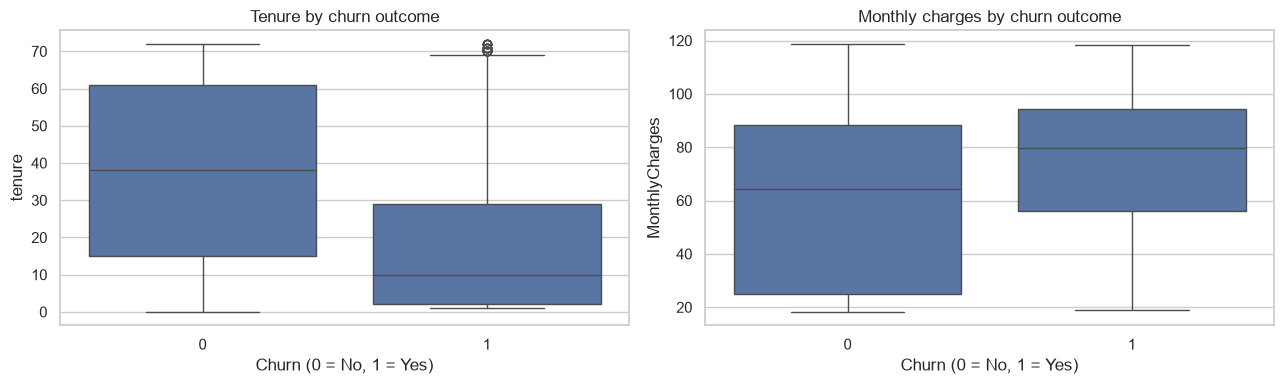

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.boxplot(data=data, x="Churn", y="tenure", ax=axes[0])
axes[0].set_title("Tenure by churn outcome")
axes[0].set_xlabel("Churn (0 = No, 1 = Yes)")

sns.boxplot(data=data, x="Churn", y="MonthlyCharges", ax=axes[1])
axes[1].set_title("Monthly charges by churn outcome")
axes[1].set_xlabel("Churn (0 = No, 1 = Yes)")

plt.tight_layout()
plt.show()

,churn_percent
Contract,
Month-to-month,42.7
One year,11.3
Two year,2.8


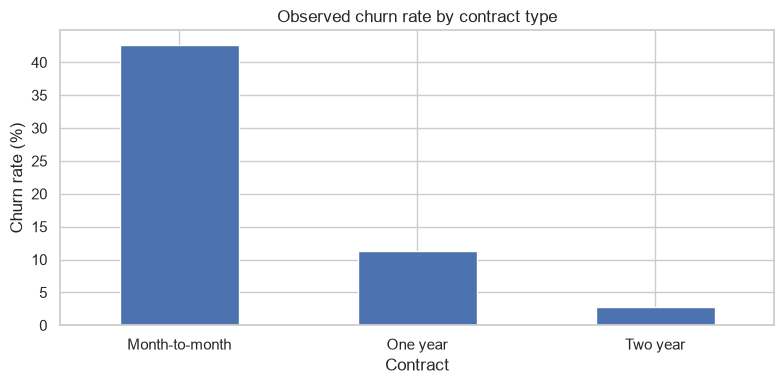

In [7]:
churn_by_contract = (
    data.groupby("Contract", observed=False)["Churn"]
    .mean()
    .sort_values(ascending=False)
    .mul(100)
)
display(churn_by_contract.rename("churn_percent").round(1).to_frame())

ax = churn_by_contract.plot(kind="bar", figsize=(8, 4))
ax.set_title("Observed churn rate by contract type")
ax.set_xlabel("Contract")
ax.set_ylabel("Churn rate (%)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 6. Train/test split and preprocessing

A stratified split keeps the target proportion similar in both subsets. The preprocessing transformer handles numeric and categorical columns separately.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    features,
    target,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=target,
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()


def make_preprocessor():
    """Create independent preprocessing steps for each model."""
    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipeline, numeric_features),
            ("categorical", categorical_pipeline, categorical_features),
        ],
        remainder="drop",
    )


print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Training rows: 5634
Test rows: 1409
Numeric features: 4
Categorical features: 15


## 7. Train and compare models

Both models use the same split and preprocessing. Class weighting is enabled to make the classifiers more attentive to the less frequent churn class. This does not automatically determine the best decision threshold for a business use case.

In [9]:
models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocess", make_preprocessor()),
        ("classifier", LogisticRegression(
            max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
        )),
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocess", make_preprocessor()),
        ("classifier", RandomForestClassifier(
            n_estimators=400,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]),
}

metric_rows = []
fitted_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
    }
    metric_rows.append(row)
    fitted_models[name] = model

    print(f"\n{name}")
    print(classification_report(y_test, predictions, zero_division=0))

results = pd.DataFrame(metric_rows).set_index("Model").sort_values("ROC-AUC", ascending=False)
display(results.round(3))


Logistic Regression
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


Random Forest
              precision    recall  f1-score   support

           0       0.88      0.78      0.83      1035
           1       0.53      0.71      0.61       374

    accuracy                           0.76      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.76      0.77      1409



,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.738,0.504,0.783,0.614,0.841
Random Forest,0.759,0.534,0.706,0.608,0.835


## 8. Visual model evaluation

Compare ROC curves and confusion matrices. Recall measures the fraction of observed churners detected; precision measures how many predicted churners actually churned in this test sample.

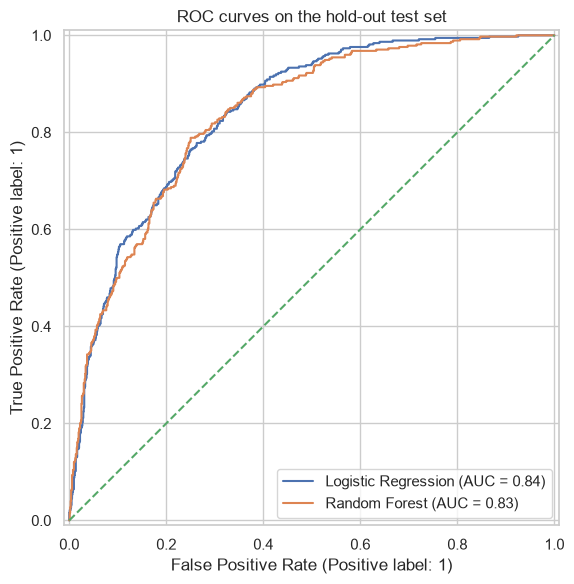

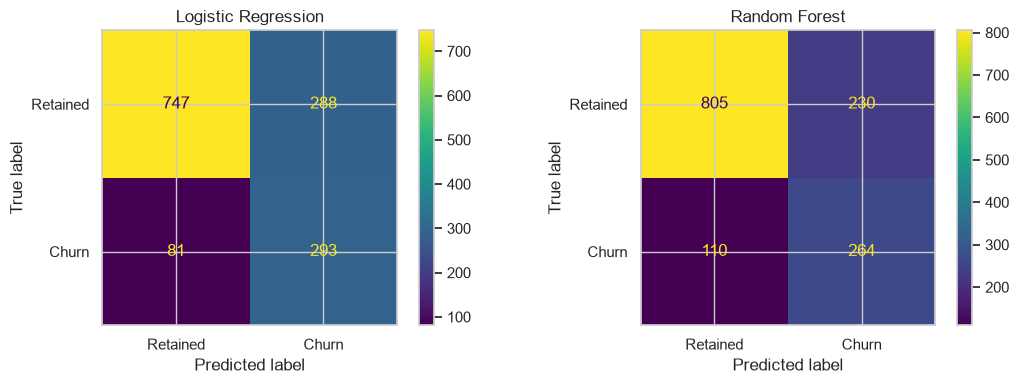

In [10]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, model in fitted_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
ax.set_title("ROC curves on the hold-out test set")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(fitted_models), figsize=(11, 4))
for ax, (name, model) in zip(axes, fitted_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, display_labels=["Retained", "Churn"], ax=ax
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 9. Random Forest feature importance

Feature importance is calculated after one-hot encoding. It reflects how this fitted Random Forest used the available features; it is not evidence that a feature causes churn.

,importance
numeric__tenure,0.1275
numeric__TotalCharges,0.1239
numeric__MonthlyCharges,0.0987
categorical__Contract_Month-to-month,0.0962
categorical__Contract_Two year,0.0480
categorical__OnlineSecurity_No,0.0467
categorical__TechSupport_No,0.0402
categorical__InternetService_Fiber optic,0.0356
categorical__PaymentMethod_Electronic check,0.0304
categorical__Contract_One year,0.0179


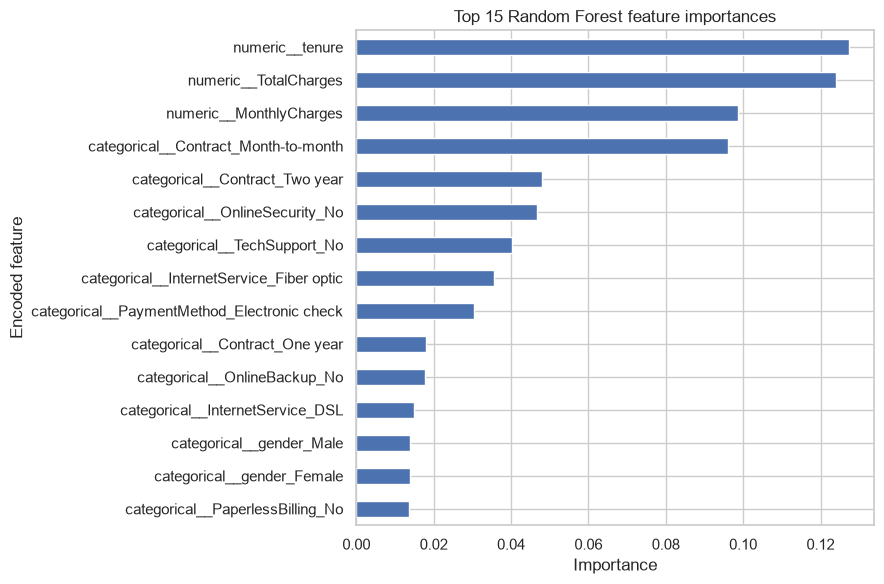

In [11]:
rf_pipeline = fitted_models["Random Forest"]
rf_preprocessor = rf_pipeline.named_steps["preprocess"]
rf_classifier = rf_pipeline.named_steps["classifier"]

feature_names = rf_preprocessor.get_feature_names_out()
importance = pd.Series(
    rf_classifier.feature_importances_, index=feature_names
).sort_values(ascending=False)

display(importance.head(15).rename("importance").to_frame().round(4))

ax = importance.head(15).sort_values().plot(kind="barh", figsize=(9, 6))
ax.set_title("Top 15 Random Forest feature importances")
ax.set_xlabel("Importance")
ax.set_ylabel("Encoded feature")
plt.tight_layout()
plt.show()

## 10. Summary and next steps

The output above provides the observed metrics and model diagnostics for this specific random split. Before treating a model as useful, consider:

1. Repeating evaluation with stratified cross-validation and reporting variability.
2. Selecting a probability threshold using realistic contact costs and customer outcomes, not accuracy alone.
3. Checking calibration and subgroup error rates.
4. Testing on newer, independently collected data before any operational use.
5. Reviewing privacy, fairness, and customer-impact implications.

**Interpretation caution:** this is a historical sample dataset for a fictional provider. It does not demonstrate that any intervention will reduce churn, and it is not a production-ready decision system.

In [12]:
# Select the best model by ROC-AUC for an optional local artifact.
best_model_name = results.index[0]
best_model = fitted_models[best_model_name]
print("Top model by this test split's ROC-AUC:", best_model_name)

# Save locally only; model files are excluded from Git by .gitignore.
import joblib
from pathlib import Path

model_dir = REPO_ROOT / "models"
model_dir.mkdir(exist_ok=True)
model_path = model_dir / "best_model.joblib"
joblib.dump(best_model, model_path)
print("Saved model to:", model_path)

Top model by this test split's ROC-AUC: Logistic Regression
Saved model to: c:\Users\proti\customer-churn-prediction\models\best_model.joblib


## References

- IBM, [Telco Customer Churn sample dataset repository](https://github.com/IBM/telco-customer-churn-on-icp4d) (archived repository).
- IBM, [Telco Customer Churn sample documentation](https://www.ibm.com/docs/en/cognos-analytics/11.1.0?topic=samples-telco-customer-churn).
- Scikit-learn, [Pipeline and composite estimators](https://scikit-learn.org/stable/modules/compose.html).
- Scikit-learn, [Model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html).